# Import libraries

In [1]:
import os
import re
import numpy as np
import pandas as pd
from pathlib import Path
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns
sns.set_style("whitegrid")

# import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

from matplotlib.colors import TwoSlopeNorm

In [2]:
mpl.rcParams['font.family'] = 'Arial'
params = {'figure.figsize': (12, 8), #14, 12
          'font.size' : 28,
         'axes.labelsize': 28,
         'axes.titlesize': 26,
         'xtick.labelsize':26,
         'ytick.labelsize':26,
         'legend.fontsize': 26,
         'legend.title_fontsize': 'large',
         'axes.facecolor': '#FFFFFF',  # Background color
    'axes.grid': True,         # Enable grid
    'grid.color': '#DDDDDD',   # Light gray gridlines
    'grid.linestyle': '-',     # Solid gridlines
    'grid.linewidth': 0.8,     # Thin gridlines
    'axes.edgecolor': '#CCCCCC',  # Light gray axis edges
    'axes.linewidth': 1.0,     # Thin axis edges
    'lines.linewidth': 2,      # Line width for plots
    'axes.xmargin': 0.01  }

# 'axes.axisbelow': 'True',
# 'axes.prop_cycle': colors,
mpl.rcParams.update(params)

# Import data

In [4]:
all_protein = pd.read_excel('Raw_enzyme_data.xlsx', sheet_name = None)
all_protein

{'Protein':    Protein conc in [ug/ul] Unnamed: 1 Unnamed: 2  Unnamed: 3 Unnamed: 4  \
 0                    Roots          D          Z         NaN     Shoots   
 1                      ER1    0.10978   0.103887         NaN        ES1   
 2                      ER2   0.169661   0.107239         NaN        ES2   
 3                      ER3   0.216234   0.127346         NaN        ES3   
 4                      ER4   0.264471   0.177614         NaN        ES4   
 5                      ER5   0.227046   0.103887         NaN        ES5   
 6                      ER6   0.196274   0.134048         NaN        ES6   
 7                      ER7   0.129741   0.060322         NaN        ES7   
 8                      ER8   0.234531   0.067024         NaN        ES8   
 9                      ER9    0.05988   0.070375         NaN        ES9   
 10                    ER10    0.02994   0.060322         NaN       ES10   
 11                    ER11   0.016944   0.148866         NaN       ES11   
 

In [5]:
data_path = Path.cwd()

results_folder = 'Figures'
results_path = data_path / results_folder
results_path.mkdir(parents=True, exist_ok = True)
os.chdir(results_path)

## Process data

In [6]:
all_protein.keys()

dict_keys(['Protein', 'AGPase', 'Aldolase', 'FK', 'G6PDH', 'HXK', 'PFK', 'PGI', 'PGM', 'UGPase', 'VacInv', 'CytInv', 'CwInv', 'CwPOX', 'APX', 'CAT', 'GR', 'MDHAR', 'POX'])

In [7]:
key_to_remove = 'Protein'  # Replace 'key_name' with the actual key you want to remove

# Check if the key exists to avoid KeyError
if key_to_remove in all_protein:
    del all_protein[key_to_remove]

In [8]:
all_protein.keys()

dict_keys(['AGPase', 'Aldolase', 'FK', 'G6PDH', 'HXK', 'PFK', 'PGI', 'PGM', 'UGPase', 'VacInv', 'CytInv', 'CwInv', 'CwPOX', 'APX', 'CAT', 'GR', 'MDHAR', 'POX'])

In [9]:
all_protein['AGPase'].columns

Index(['Unnamed: 0', 'Mean v [nkat/mg prot]', 'SD', 'Unnamed: 3', 'Unnamed: 4',
       'Mean v [nkat/mg prot].1', 'SD.1'],
      dtype='str')

In [10]:
def process_rootshoot_dataframe(df):
    # Select the columns to keep and rename them for consistency
    df = df.drop(df.index[0])
    df1 = df[['Unnamed: 0', 'Mean v [nkat/mg prot]', 'SD']].copy()
    df2 = df[['Unnamed: 4', 'Mean v [nkat/mg prot].1', 'SD.1']].copy()
    df2.columns = ['Unnamed: 0', 'Mean v [nkat/mg prot]', 'SD']
    
    # Append the dataframes
    result_df = pd.concat([df1, df2], axis=0, ignore_index=True)
    result_df.columns = ['ID', 'Mean v [nkat/mg prot]', 'SD']
    result_df = result_df.dropna()
    
    return result_df

In [11]:
rootshoot_data = {key: process_rootshoot_dataframe(df) for key, df in all_protein.items()}

In [12]:
rootshoot_data

{'AGPase':       ID Mean v [nkat/mg prot]        SD
 0    ER1              0.084489  0.013560
 1    ER2              0.074243  0.000000
 2    ER3                     0  0.000000
 3    ER4              0.030308  0.017506
 4    ER5              0.021519  0.016905
 ..   ...                   ...       ...
 67  DS14              0.363234  0.034219
 68  DS15              0.387544  0.003452
 69  DS16              0.145317  0.010146
 70  DS17              0.027542  0.008730
 71  DS18               0.40055  0.073234
 
 [72 rows x 3 columns],
 'Aldolase':       ID Mean v [nkat/mg prot]        SD
 0    ER1              0.044852  0.013560
 1    ER2              0.045896  0.000000
 2    ER3              0.075728  0.057722
 3    ER4                     0  0.000000
 4    ER5                     0  0.000000
 5    ER6               0.04434  0.003501
 6    ER7              0.063548  0.037777
 7    ER8              0.092768  0.044905
 8    ER9              0.428358  0.160634
 9   ER10              1.265

In [26]:
def interpret_id(id_value):

    # Extract the letter part and the numeric part using regex
        match = re.match(r"([a-zA-Z]+)(\d+)", id_value)
        if match:
            letters, number = match.groups()
        else:
            return 'Unknown', 'Unknown', 'Unknown'  # Return defaults if the ID doesn't match the expected format
        
            
        # Determine experiment based on the first letter
        experiment = (
        'Y1' if number in ['1', '2', '3', '4', '5', '6'] 
        else 'Y2' if number in ['13', '14', '15', '16', '17', '18'] 
        else 'Controlled'
        )
        
        # Determine species based on the first letter
        species_dict = {'E': 'E. vaginatum', 'D': 'D. flexuosa', 'C' : 'Control'} 
        species = species_dict.get(letters[0], 'Unknown')
        
        # Determine plant part based on the second letter
        plant_part_dict = {'R': 'Root', 'S': 'Shoot'} 
        plant_part = plant_part_dict.get(letters[1], 'Unknown')
    
        # Determine treatment based on the number
        treatment_dict = {
            '1': 'Control',
            '2': 'R freezing',
            '3': 'R+S freezing', 
            '4' : 'R freezing recovery',
            '5' : 'R+S freezing recovery', 
            '6' : 'Control', #  
            '7' : 'Control',
            '8' : 'R chilling',
            '9' : 'R+S chilling', 
            '10' : 'R chilling recovery',
            '11' : 'R+S chilling recovery',
            '12' : 'Control',
            '13' : 'Control', 
            '14' : 'R freezing', 
            '15' : 'R+S freezing', 
            '16' : 'R freezing recovery', 
            '17' : 'R+S freezing recovery', 
            '18' : 'Control'
            
        }
        treatment_ID = treatment_dict.get(number, 'Unknown')
    
        return experiment, species, plant_part, treatment_ID

In [27]:
for key, df in rootshoot_data.items():
    df[['Experiment', 'Species', 'Plant part','Treatment']] = df['ID'].apply(lambda x: pd.Series(interpret_id(x)))

    # Remove rows containing "recovery" in Treatment_ID for this analysis
    df = df[~df['Treatment'].str.contains('recovery', case=False, na=False)]
    
    rootshoot_data[key] = df 

In [28]:
rootshoot_data

{'AGPase':       ID Mean v [nkat/mg prot]        SD  Experiment       Species Plant part  \
 0    ER1              0.084489  0.013560          Y1  E. vaginatum       Root   
 1    ER2              0.074243  0.000000          Y1  E. vaginatum       Root   
 2    ER3                     0  0.000000          Y1  E. vaginatum       Root   
 5    ER6              0.016336  0.000000          Y1  E. vaginatum       Root   
 6    ER7              0.033539  0.007061  Controlled  E. vaginatum       Root   
 7    ER8                     0  0.000000  Controlled  E. vaginatum       Root   
 8    ER9              0.745802  0.000000  Controlled  E. vaginatum       Root   
 11  ER12              0.063435  0.000000  Controlled  E. vaginatum       Root   
 12   DR1               0.30291  0.020653          Y1   D. flexuosa       Root   
 13   DR2              0.165661  0.018709          Y1   D. flexuosa       Root   
 14   DR3              0.216627  0.021773          Y1   D. flexuosa       Root   
 17   

In [29]:
rootshoot_data.keys()

dict_keys(['AGPase', 'Aldolase', 'FK', 'G6PDH', 'HXK', 'PFK', 'PGI', 'PGM', 'UGPase', 'VacInv', 'CytInv', 'CwInv', 'CwPOX', 'APX', 'CAT', 'GR', 'MDHAR', 'POX'])

## Merge data into one dataframe

In [30]:
temp_dfs = []

# Loop through the dictionary items
for key, df in rootshoot_data.items():
    # Add a new column with the key name
    df['Enzyme'] = key
    # Append the modified DataFrame to the list
    temp_dfs.append(df)

# Concatenate all DataFrames in the list
rootshoot_final = pd.concat(temp_dfs, ignore_index=True)

enzyme_function_dict = {'CwInv' : 'Sucrolytic activity', 'VacInv' : 'Sucrolytic activity', 'CytInv' : 'Sucrolytic activity',
                         'FK' : 'Glycolysis', 'HXK' : 'Glycolysis', 'PFK' : 'Glycolysis', 
                        'UGPase' : 'Carbon storage', 'AGPase' : 'Carbon storage', 'PGM' : 'Carbon storage',
                        'PGI' : 'Carbon redistribution', 'Aldolase' : 'Carbon redistribution',  'G6PDH': 'Carbon redistribution',
                        }

rootshoot_final['Enzyme function'] = rootshoot_final['Enzyme'].map(lambda x: enzyme_function_dict.get(x, 'Antioxidant'))

# rootshoot_final['Treatment'] = np.where(
#     rootshoot_final['Treatment_ID'].str.contains('recovery', na=False),
#     rootshoot_final['Treatment_ID'].str.extract(r'(.*) recovery')[0],
#     rootshoot_final['Treatment_ID']
#     )

# rootshoot_final['Stage'] = np.where(
#     rootshoot_final['Treatment_ID'].str.contains('recovery', na=False),
#     'Recovery',
#     'Treatment'
# )

rootshoot_final['Mean v [nkat/mg prot]'] = pd.to_numeric(rootshoot_final['Mean v [nkat/mg prot]'], errors='coerce')

# rootshoot_final['Treatment_Experiment'] = rootshoot_final['Treatment_ID'] + ' (' + rootshoot_final['Experiment'] + ')'

# rootshoot_final = rootshoot_final[['ID', 'Mean v [nkat/mg prot]', 'SD', 'Species',
#        'Plant part', 'Enzyme', 'Enzyme function', 'Experiment',  'Treatment', 'Stage',  'Treatment_ID', 'Treatment_Experiment']]

rootshoot_final = rootshoot_final[['ID', 'Mean v [nkat/mg prot]', 'SD', 'Species',
       'Plant part', 'Enzyme', 'Enzyme function', 'Experiment',  'Treatment']]

# Display the final DataFrame
rootshoot_final

,ID,Mean v [nkat/mg prot],SD,Species,Plant part,Enzyme,Enzyme function,Experiment,Treatment
0,ER1,0.084489,0.013560,E. vaginatum,Root,AGPase,Carbon storage,Y1,Control
1,ER2,0.074243,0.000000,E. vaginatum,Root,AGPase,Carbon storage,Y1,R freezing
2,ER3,0.000000,0.000000,E. vaginatum,Root,AGPase,Carbon storage,Y1,R+S freezing
3,ER6,0.016336,0.000000,E. vaginatum,Root,AGPase,Carbon storage,Y1,Control
4,ER7,0.033539,0.007061,E. vaginatum,Root,AGPase,Carbon storage,Controlled,Control
...,...,...,...,...,...,...,...,...,...
837,ES18,6.353723,6.194677,E. vaginatum,Shoot,POX,Antioxidant,Y2,Control
838,DS13,0.824926,0.015129,D. flexuosa,Shoot,POX,Antioxidant,Y2,Control
839,DS14,2.076061,0.339673,D. flexuosa,Shoot,POX,Antioxidant,Y2,R freezing
840,DS15,2.228860,0.069385,D. flexuosa,Shoot,POX,Antioxidant,Y2,R+S freezing


# Plot control results - all

In [74]:
def plot_controls_whisker(df, enzyme_type):
    
    
    control_data = df[df['Treatment'] == 'Control']
    
    # Get unique species and plant parts
    species_list = control_data['Species'].unique()
    plant_parts = control_data['Plant part'].unique()
    
    for species in species_list:
        for plant_part in plant_parts:
            # Filter data for current species and plant part
            species_part_data = control_data[(control_data['Species'] == species) & (control_data['Plant part'] == plant_part)]

            # Create a figure and axis for the plot
            fig, ax = plt.subplots(figsize=(14, 10))
            
           # PLot average of all controls
            sns.boxplot(data=species_part_data, x='Enzyme function', y='Mean v [nkat/mg prot]', ax=ax, color = 'gray', 
                       boxprops=dict(alpha=0.5)) 

            # Plot - Jitter different experiments
            sns.stripplot(  
            data=species_part_data, 
            x='Enzyme function', 
            y='Mean v [nkat/mg prot]', 
            hue='Experiment', 
            ax=ax, 
            dodge=True,  # Separate points by hue
            jitter=True, # Add jitter to avoid overlapping points
            size = 8, 
            edgecolor = 'black',
            linewidth = 0.8,
            # palette='tab10',  # Choose a color palette
            alpha=1  # Adjust transparency of Catter points
            )

            
            # Set plot labels and title
            ax.set_title(rf'$\it{{{species}}}$ {plant_part}s')
            ax.set_xlabel("")
            ax.set_xticks(range(len(species_part_data['Enzyme function'].unique())))
            ax.set_xticklabels(species_part_data['Enzyme function'].unique(), rotation=45) #, ha='right'
            ax.set_ylabel('Specific activity [nkat/mg prot]')

            # plt.savefig(f'controls_{species}_{plant_part}.png', dpi=300, bbox_inches='tight')
            # Show the plot
            plt.show()

In [76]:
# plot_controls_whisker(rootshoot_final, 'All')

# Calculate Log2 fold change

In [77]:
all_enzymes = rootshoot_final.copy()

In [78]:
all_enzymes.head()

,ID,Mean v [nkat/mg prot],SD,Species,Plant part,Enzyme,Enzyme function,Experiment,Treatment
0,ER1,0.084489,0.013560,E. vaginatum,Root,AGPase,Carbon storage,Y1,Control
1,ER2,0.074243,0.000000,E. vaginatum,Root,AGPase,Carbon storage,Y1,R freezing
2,ER3,0.000000,0.000000,E. vaginatum,Root,AGPase,Carbon storage,Y1,R+S freezing
3,ER6,0.016336,0.000000,E. vaginatum,Root,AGPase,Carbon storage,Y1,Control
4,ER7,0.033539,0.007061,E. vaginatum,Root,AGPase,Carbon storage,Controlled,Control


### Treatment_ID - Control calculations

In [79]:
def calculate_log_fold_change_treatments(group):
    # Calculate the average control value
    control_value = group.loc[group['Treatment'] == 'Control', 'Mean v [nkat/mg prot]']
    
    if not control_value.empty:
        # control_mean = control_values.mean()
        control_value = control_value.mean()

        if control_value <= 0:
            group['Mean v Difference'] = None
            group['Fold Change'] = None
            group['Log2 Fold Change'] = None
        else:
            # Subtract the average control value from all Mean v values in the group
            group['Mean v Difference'] = group['Mean v [nkat/mg prot]'] - control_value
    
            # Calculate the fold change for all Mean v values in the group
            group['Fold Change'] = group['Mean v [nkat/mg prot]'] / control_value
    
            # Calculate the log2 fold change, handling zero or negative values
            group['Log2 Fold Change'] = np.log2(group['Fold Change'].replace(0, np.nan))
    
        
    else:
        group['Mean v Difference'] = None
        group['Fold Change'] = None
        group['Log2 Fold Change'] = None

    group['Log2 Fold Change'] = group['Log2 Fold Change'].replace(np.nan, 0).astype(float)
        
    return group

In [80]:
def apply_log_fc_treatments(df):

    df_trt = df.groupby(['Species', 'Plant part', 'Enzyme', 'Experiment'], observed=True).apply( 
    calculate_log_fold_change_treatments, include_groups = False)

    df_trt = df_trt.reset_index()
    df_trt.drop('level_4', axis = 1, inplace = True)
    
    df_trt = df_trt[df_trt['Treatment'] != 'Control']
    # df_trt = df_trt[~df_trt['Treatment_Experiment'].str.contains('recovery')]
    # df_trt = df_trt[df_trt['Stage'] == 'Treatment']
   
    # df_trt.to_excel(f'{df}_logfc_treatments.xlsx')
    return df_trt

In [81]:
all_data = apply_log_fc_treatments(all_enzymes)

In [82]:
all_data

,Species,Plant part,Enzyme,Experiment,ID,Mean v [nkat/mg prot],SD,Enzyme function,Treatment,Mean v Difference,Fold Change,Log2 Fold Change
1,D. flexuosa,Root,AGPase,Controlled,DR8,0.418797,0.005737,Carbon storage,R chilling,-0.016955,0.961091,-0.057255
2,D. flexuosa,Root,AGPase,Controlled,DR9,0.875839,0.168262,Carbon storage,R+S chilling,0.440088,2.009953,1.007162
5,D. flexuosa,Root,AGPase,Y1,DR2,0.165661,0.018709,Carbon storage,R freezing,0.014206,1.093795,0.129342
6,D. flexuosa,Root,AGPase,Y1,DR3,0.216627,0.021773,Carbon storage,R+S freezing,0.065172,1.430303,0.516321
9,D. flexuosa,Root,AGPase,Y2,DR14,0.000359,0.000359,Carbon storage,R freezing,-0.009611,0.03599,-4.796261
...,...,...,...,...,...,...,...,...,...,...,...,...
832,E. vaginatum,Shoot,VacInv,Controlled,ES9,5.640469,1.544198,Sucrolytic activity,R+S chilling,-8.786694,0.390962,-1.354901
835,E. vaginatum,Shoot,VacInv,Y1,ES2,0.633711,0.064014,Sucrolytic activity,R freezing,-8.228748,0.071505,-3.805810
836,E. vaginatum,Shoot,VacInv,Y1,ES3,2.038343,0.302600,Sucrolytic activity,R+S freezing,-6.824116,0.229997,-2.120310
839,E. vaginatum,Shoot,VacInv,Y2,ES14,28.289510,18.869737,Sucrolytic activity,R freezing,0.42226,1.015153,0.021697


# Merge outdoors (Y1 and Y2) and separate controlled

In [83]:
all_data.head()

,Species,Plant part,Enzyme,Experiment,ID,Mean v [nkat/mg prot],SD,Enzyme function,Treatment,Mean v Difference,Fold Change,Log2 Fold Change
1,D. flexuosa,Root,AGPase,Controlled,DR8,0.418797,0.005737,Carbon storage,R chilling,-0.016955,0.961091,-0.057255
2,D. flexuosa,Root,AGPase,Controlled,DR9,0.875839,0.168262,Carbon storage,R+S chilling,0.440088,2.009953,1.007162
5,D. flexuosa,Root,AGPase,Y1,DR2,0.165661,0.018709,Carbon storage,R freezing,0.014206,1.093795,0.129342
6,D. flexuosa,Root,AGPase,Y1,DR3,0.216627,0.021773,Carbon storage,R+S freezing,0.065172,1.430303,0.516321
9,D. flexuosa,Root,AGPase,Y2,DR14,0.000359,0.000359,Carbon storage,R freezing,-0.009611,0.03599,-4.796261


In [84]:
all_data_controlled = all_data[all_data['Experiment'] == 'Controlled']
all_data_out = all_data[all_data['Experiment'] != 'Controlled']

In [85]:
treatment_order = ['R+S chilling', 'R chilling']

all_data_controlled['Treatment'] = pd.Categorical(
        all_data_controlled['Treatment'], 
        categories=treatment_order, 
        ordered=True  # Enforce the specified order
    )
all_data_controlled

,Species,Plant part,Enzyme,Experiment,ID,Mean v [nkat/mg prot],SD,Enzyme function,Treatment,Mean v Difference,Fold Change,Log2 Fold Change
1,D. flexuosa,Root,AGPase,Controlled,DR8,0.418797,0.005737,Carbon storage,R chilling,-0.016955,0.961091,-0.057255
2,D. flexuosa,Root,AGPase,Controlled,DR9,0.875839,0.168262,Carbon storage,R+S chilling,0.440088,2.009953,1.007162
13,D. flexuosa,Root,APX,Controlled,DR8,4.698362,0.936523,Antioxidant,R chilling,0.238904,1.053572,0.075289
14,D. flexuosa,Root,APX,Controlled,DR9,5.225122,1.864664,Antioxidant,R+S chilling,0.765664,1.171694,0.228596
25,D. flexuosa,Root,Aldolase,Controlled,DR8,0.000000,0.000000,Carbon redistribution,R chilling,-0.03269,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
808,E. vaginatum,Shoot,POX,Controlled,ES9,0.427724,0.086695,Antioxidant,R+S chilling,-0.222124,0.658191,-0.603423
819,E. vaginatum,Shoot,UGPase,Controlled,ES8,0.000000,0.000000,Carbon storage,R chilling,-2.244186,0.0,0.000000
820,E. vaginatum,Shoot,UGPase,Controlled,ES9,2.050084,0.225131,Carbon storage,R+S chilling,-0.194101,0.913509,-0.130509
831,E. vaginatum,Shoot,VacInv,Controlled,ES8,34.209947,3.870414,Sucrolytic activity,R chilling,19.782783,2.371218,1.245628


In [86]:
treatment_order = ['R+S freezing', 'R freezing']

all_data_out['Treatment'] = pd.Categorical(
        all_data_out['Treatment'], 
        categories=treatment_order, 
        ordered=True  # Enforce the specified order
    )
all_data_out

,Species,Plant part,Enzyme,Experiment,ID,Mean v [nkat/mg prot],SD,Enzyme function,Treatment,Mean v Difference,Fold Change,Log2 Fold Change
5,D. flexuosa,Root,AGPase,Y1,DR2,0.165661,0.018709,Carbon storage,R freezing,0.014206,1.093795,0.129342
6,D. flexuosa,Root,AGPase,Y1,DR3,0.216627,0.021773,Carbon storage,R+S freezing,0.065172,1.430303,0.516321
9,D. flexuosa,Root,AGPase,Y2,DR14,0.000359,0.000359,Carbon storage,R freezing,-0.009611,0.03599,-4.796261
10,D. flexuosa,Root,AGPase,Y2,DR15,0.000000,0.000000,Carbon storage,R+S freezing,-0.009969,0.0,0.000000
17,D. flexuosa,Root,APX,Y1,DR2,2.093447,0.699520,Antioxidant,R freezing,-5.519466,0.274986,-1.862568
...,...,...,...,...,...,...,...,...,...,...,...,...
828,E. vaginatum,Shoot,UGPase,Y2,ES15,5.149072,0.698307,Carbon storage,R+S freezing,-5.02552,0.506072,-0.982587
835,E. vaginatum,Shoot,VacInv,Y1,ES2,0.633711,0.064014,Sucrolytic activity,R freezing,-8.228748,0.071505,-3.805810
836,E. vaginatum,Shoot,VacInv,Y1,ES3,2.038343,0.302600,Sucrolytic activity,R+S freezing,-6.824116,0.229997,-2.120310
839,E. vaginatum,Shoot,VacInv,Y2,ES14,28.289510,18.869737,Sucrolytic activity,R freezing,0.42226,1.015153,0.021697


## Plot Heatmaps

In [87]:
def relative_heatmap_all(df, group):
   
    species = df['Species'].unique()
    plant_parts = ['Shoot', 'Root']

    panel_labels = [['A', 'B'],
                ['C', 'D']]
    
    fig, axes = plt.subplots(2, len(species),
        figsize=(18, 18), constrained_layout=False)
    
    # fig.set_constrained_layout_pads(hspace=0.05, wspace=0.05)
    fig.subplots_adjust(right=0.90, hspace = 0.3, wspace = 0.3)

    cbar_ax = fig.add_axes([0.92, 0.30, 0.02, 0.40])

    for sp_idx, sp in enumerate(species):
        
        df_copy = df[df['Species'] == sp]

        for row, plant_part in enumerate(plant_parts):


            col = sp_idx
            ax = axes[row, col]

            ax.text(
                -0.12, 1.02,                    # x, y in axes coordinates
                panel_labels[row][col],
                transform=ax.transAxes,
                fontsize=42,                    # adjust size as desired
                fontweight='bold',
                va='bottom',
                ha='left'
            )

            
            trt_part_data = df_copy[
                (df_copy['Plant part'] == plant_part)
            ]

            heatmap_data = trt_part_data.pivot_table(
                index='Enzyme function',
                columns='Treatment',
                values='Log2 Fold Change',
                observed=True
            )

            # Only show the colour bar on the final subplot
            show_cbar = (row == 0) and (col == axes.shape[1] - 1)
            
            sns.heatmap(
                heatmap_data,
                annot=False,
                fmt='.2f',
                cmap='seismic',
                norm=TwoSlopeNorm(vmin=-5, vcenter=0, vmax=5),
                ax=ax,
                cbar=show_cbar,
                cbar_ax=cbar_ax if show_cbar else None,
                cbar_kws={
                    'label': 'Log2 Fold Change',
                    'ticks': [-4, -2, 0, 2, 4]
                } if show_cbar else None
            )

            # Set titles
            ax.set_title(
                rf'$\it{{{sp}}}$' + f' {plant_part}s',
                pad=20,
                fontsize=30
            )
            
            # Show y-axis labels only on the first column
            if col == 0:
                ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
            else:
                ax.set_yticks([])
                ax.set_yticklabels([])

            # Wrap x-axis labels
            x_labels = [
                textwrap.fill(label.get_text(), width=12)
                for label in ax.get_xticklabels()
            ]
            ax.set_xticklabels(x_labels, rotation=0)

            ax.set_xlabel('')
            ax.set_ylabel('')

    plt.savefig(f'{group}.png', dpi=300, bbox_inches='tight')
    plt.show()

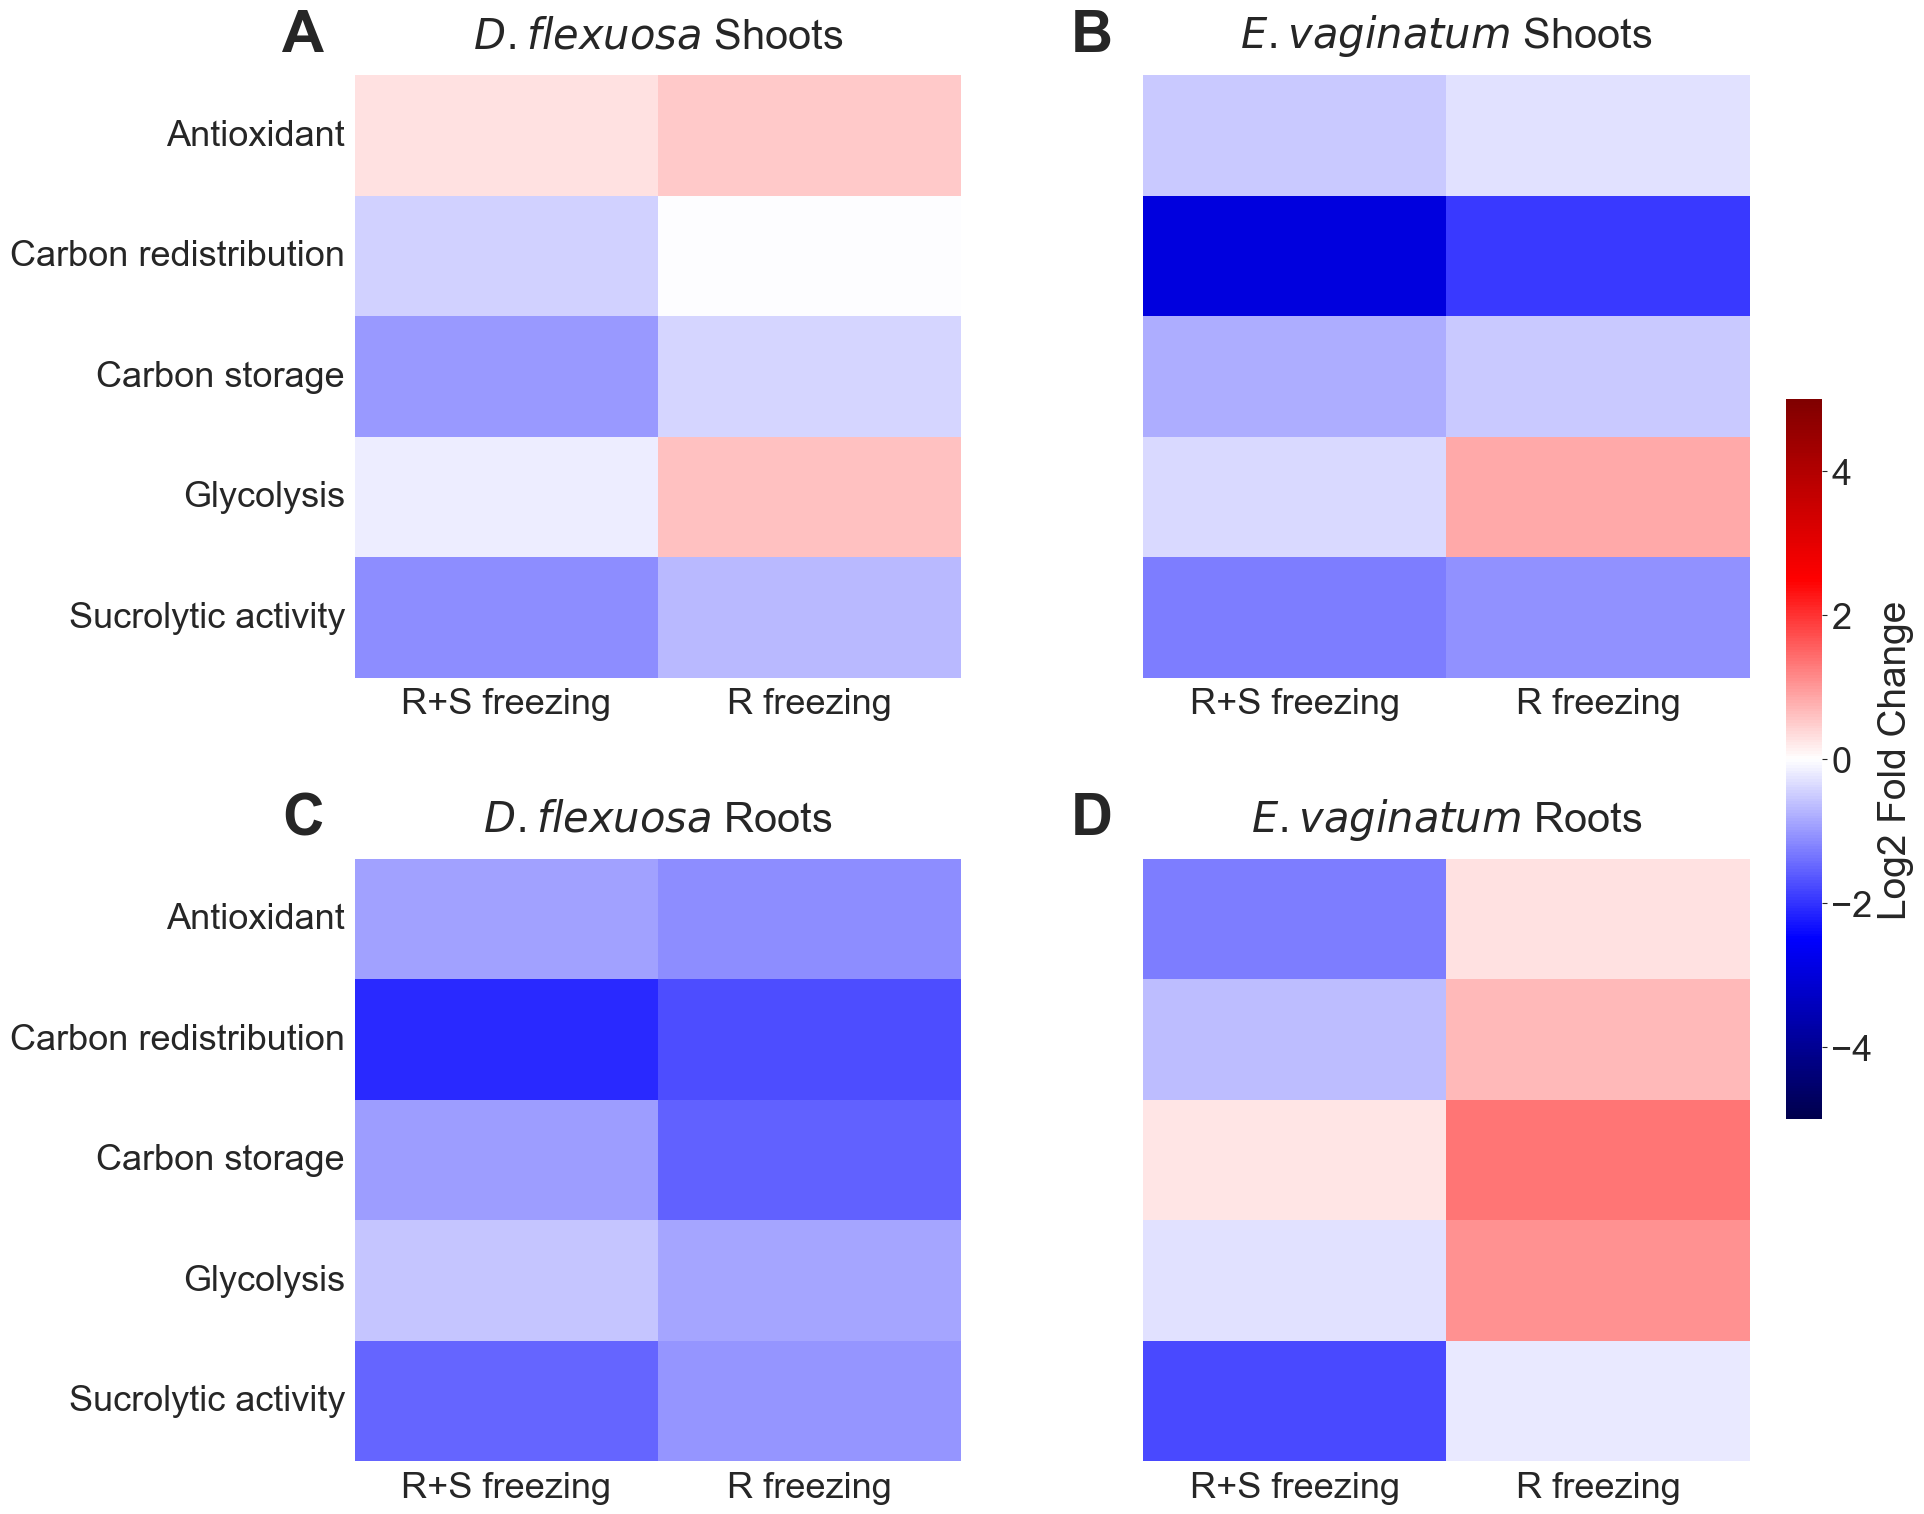

In [88]:
relative_heatmap_all(all_data_out, "outdoors")

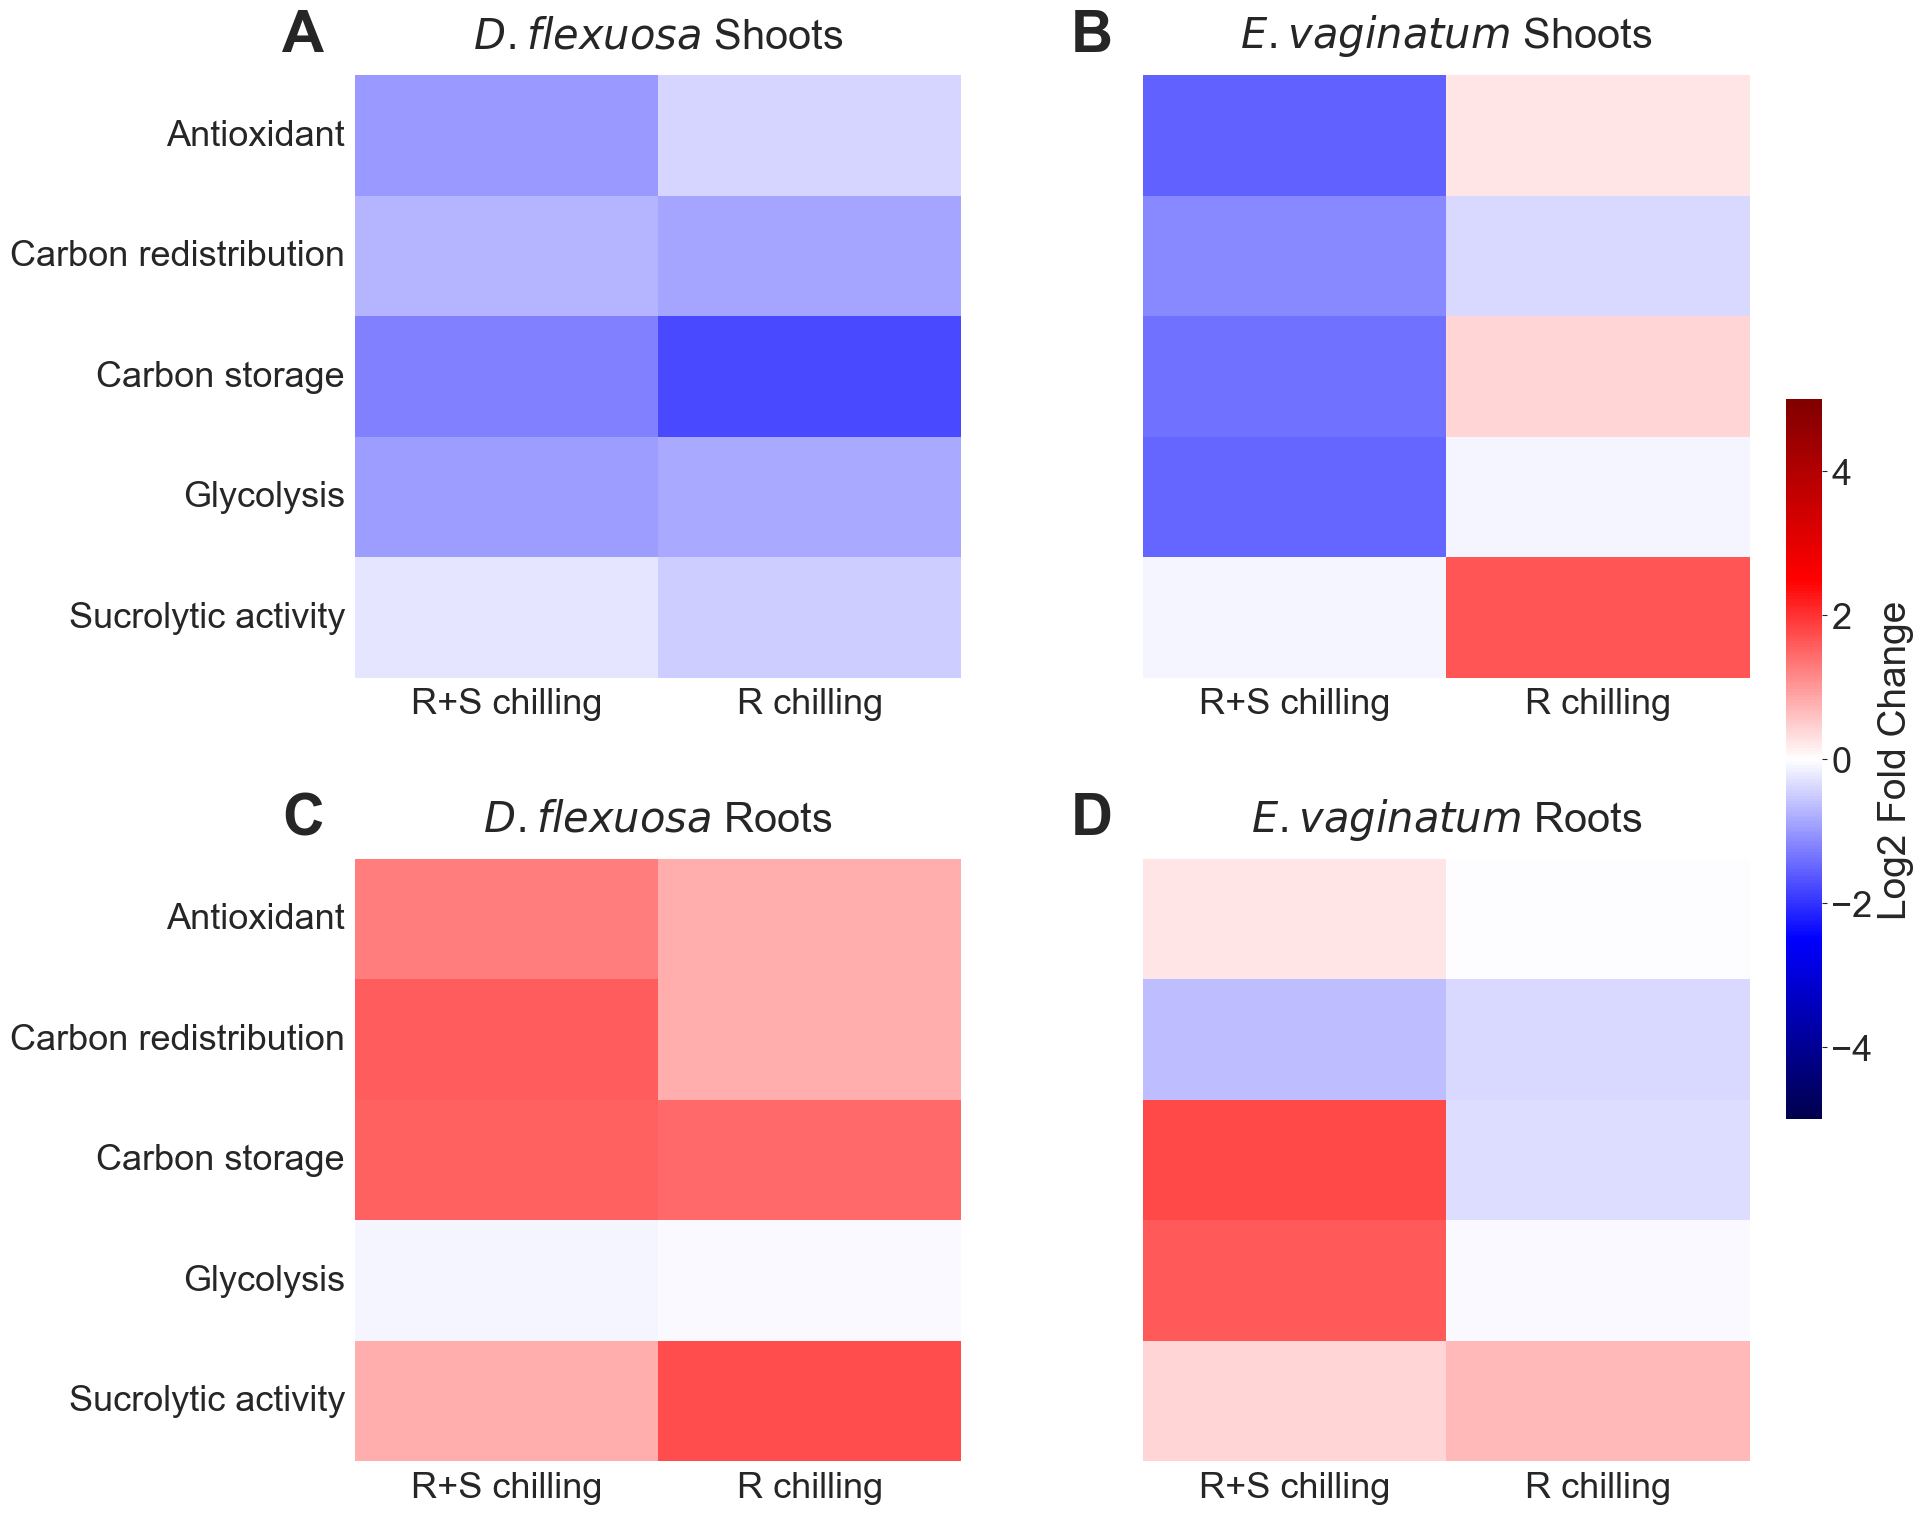

In [89]:
relative_heatmap_all(all_data_controlled, "controlled")

# Save csvs for Statistics --> R

In [90]:
results_folder = 'Statistics'
results_path = data_path / results_folder
results_path.mkdir(parents=True, exist_ok = True)
os.chdir(results_path)

In [91]:
all_data_out.to_csv('all_enzyme_data_outdoors.csv')

In [92]:
all_data_controlled.to_csv('all_enzyme_data_controlled.csv')